In [2]:
# Environment Setup and Execution Device Configuration
# This cell verifies GPU availability and configures the active PyTorch device.

import torch

# Check if CUDA-enabled GPU is available for acceleration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Active Execution Device:", device)

if device.type == 'cuda':
    print("GPU Model Name:", torch.cuda.get_device_name(0))

Active Execution Device: cuda
GPU Model Name: Tesla T4


In [5]:
# Data Loading, Transformation, and Validation Split
# This cell loads MNIST data, normalizes pixels to [-1, 1], and creates a 90/10 validation split.

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# Define standard normalization pipeline for single-channel grayscale images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download full MNIST training and testing sets
full_train_dataset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)

# Create 54,000 training samples and 6,000 validation samples
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Instantiate DataLoaders with mini-batch size of 64
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training Dataset Size: {len(train_dataset)} images")
print(f"Validation Dataset Size: {len(val_dataset)} images")
print(f"Test Dataset Size: {len(test_dataset)} images")

Training Dataset Size: 54000 images
Validation Dataset Size: 6000 images
Test Dataset Size: 10000 images


In [6]:
# Convolutional Neural Network Architecture
# Defines a custom CNN containing 2 convolutional blocks, max pooling, dropout, and 2 dense layers.

import torch.nn as nn

class CustomMNISTCNN(nn.Module):
    def __init__(self):
        super(CustomMNISTCNN, self).__init__()

        # First Convolutional Block: 1 input channel to 32 feature channels
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)

        # Second Convolutional Block: 32 channels to 64 feature channels
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        # Spatial Downsampling: 2x2 Max Pooling with stride 2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Regularization: Dropout layer with 25 percent probability
        self.dropout = nn.Dropout(p=0.25)

        # Dense Classification Layers: 64 channels * 7x7 spatial resolution = 3136 features
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Pass through Conv1 -> ReLU -> MaxPool (Output shape: 32 x 14 x 14)
        x = self.pool(torch.relu(self.conv1(x)))

        # Pass through Conv2 -> ReLU -> MaxPool (Output shape: 64 x 7 x 7)
        x = self.pool(torch.relu(self.conv2(x)))

        # Flatten feature maps into 1D vector
        x = x.view(-1, 64 * 7 * 7)

        # Fully connected layer with ReLU and Dropout regularization
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)

        # Final classification logits for 10 digit classes
        x = self.fc2(x)
        return x

# Instantiate model and transfer parameters to active execution device
model = CustomMNISTCNN().to(device)
print(model)

CustomMNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [7]:
# Loss Criterion, Optimizer, Weight Decay, and LR Scheduler Setup
# Initializes CrossEntropyLoss, Adam with weight decay (L2 regularization), and ReduceLROnPlateau.

import torch.optim as optim

# Loss function combining LogSoftmax and Negative Log Likelihood
criterion = nn.CrossEntropyLoss()

# Adam optimizer configured with learning rate 0.0005 and L2 weight decay 1e-4
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

# Learning rate scheduler to drop LR by half when validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

print("Optimizer and Schedulers initialized successfully.")

Optimizer and Schedulers initialized successfully.


In [9]:
# Iterative Model Training and Validation Loop
# Runs training epochs, evaluates validation performance, updates LR, and saves the best model.

num_epochs = 10
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_loss = float('inf')
patience = 3
patience_counter = 0

print("Starting training process across epochs...")
for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Validation phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Step scheduler based on validation loss
    scheduler.step(epoch_val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc*100:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc*100:.2f}%")

    # Early stopping check and model checkpointing
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at Epoch {epoch+1}")
            break

# Restore best performing weights
model.load_state_dict(torch.load('best_model.pth'))
print("\nOptimal model weights restored from disk.")

Starting training process across epochs...
Epoch [1/10] | Train Loss: 0.0193, Train Acc: 99.35% | Val Loss: 0.0368, Val Acc: 99.03%
Epoch [2/10] | Train Loss: 0.0177, Train Acc: 99.41% | Val Loss: 0.0355, Val Acc: 98.97%
Epoch [3/10] | Train Loss: 0.0163, Train Acc: 99.45% | Val Loss: 0.0344, Val Acc: 99.10%
Epoch [4/10] | Train Loss: 0.0101, Train Acc: 99.70% | Val Loss: 0.0318, Val Acc: 99.05%
Epoch [5/10] | Train Loss: 0.0087, Train Acc: 99.72% | Val Loss: 0.0327, Val Acc: 99.07%
Epoch [6/10] | Train Loss: 0.0084, Train Acc: 99.74% | Val Loss: 0.0339, Val Acc: 99.05%
Epoch [7/10] | Train Loss: 0.0079, Train Acc: 99.77% | Val Loss: 0.0351, Val Acc: 99.00%
Early stopping triggered at Epoch 7

Optimal model weights restored from disk.


In [10]:
# Final Test Set Evaluation and Comprehensive Classification Metrics
# Evaluates overall accuracy and per-digit precision, recall, and F1-score.

import numpy as np
from sklearn.metrics import classification_report

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = np.mean(np.array(all_preds) == np.array(all_labels)) * 100
print(f"Overall Testing Accuracy: {test_accuracy:.2f}%\n")
print("Detailed Per-Class Classification Report:")
print(classification_report(all_labels, all_preds, digits=4))

Overall Testing Accuracy: 99.32%

Detailed Per-Class Classification Report:
              precision    recall  f1-score   support

           0     0.9929    0.9980    0.9954       980
           1     0.9974    0.9965    0.9969      1135
           2     0.9942    0.9922    0.9932      1032
           3     0.9931    0.9941    0.9936      1010
           4     0.9909    0.9959    0.9934       982
           5     0.9856    0.9944    0.9900       892
           6     0.9968    0.9875    0.9921       958
           7     0.9922    0.9942    0.9932      1028
           8     0.9948    0.9908    0.9928       974
           9     0.9930    0.9881    0.9906      1009

    accuracy                         0.9932     10000
   macro avg     0.9931    0.9932    0.9931     10000
weighted avg     0.9932    0.9932    0.9932     10000



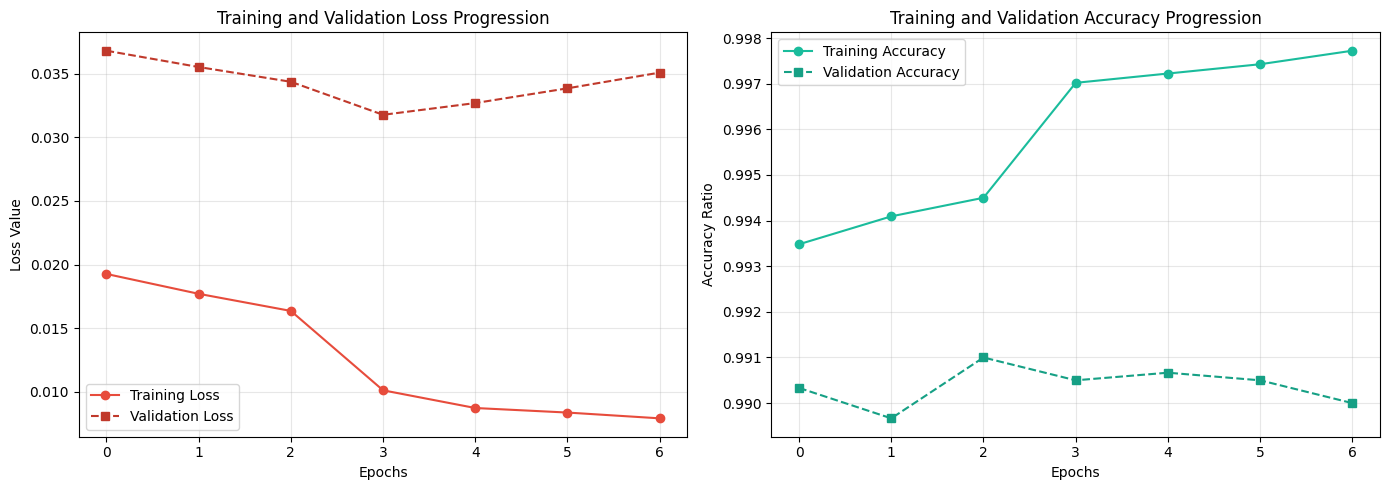

In [11]:
# Training and Validation History Curves Plotting
# Generates loss and accuracy plots using Coral Red (#E74C3C) and Teal (#1ABC9C).

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Plot training and validation loss curves
plt.subplot(1, 2, 1)
plt.plot(train_losses, color='#E74C3C', linestyle='-', marker='o', label='Training Loss')
plt.plot(val_losses, color='#C0392B', linestyle='--', marker='s', label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.title('Training and Validation Loss Progression')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot training and validation accuracy curves
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, color='#1ABC9C', linestyle='-', marker='o', label='Training Accuracy')
plt.plot(val_accuracies, color='#16A085', linestyle='--', marker='s', label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy Ratio')
plt.title('Training and Validation Accuracy Progression')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

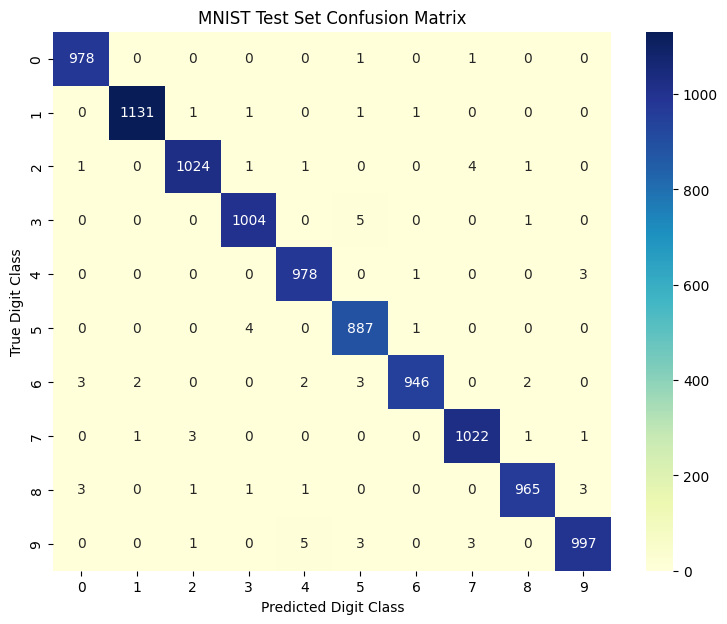

In [12]:
# Confusion Matrix Visualization
# Generates confusion matrix heatmap utilizing the YlGnBu color palette.

import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.xlabel('Predicted Digit Class')
plt.ylabel('True Digit Class')
plt.title('MNIST Test Set Confusion Matrix')
plt.show()

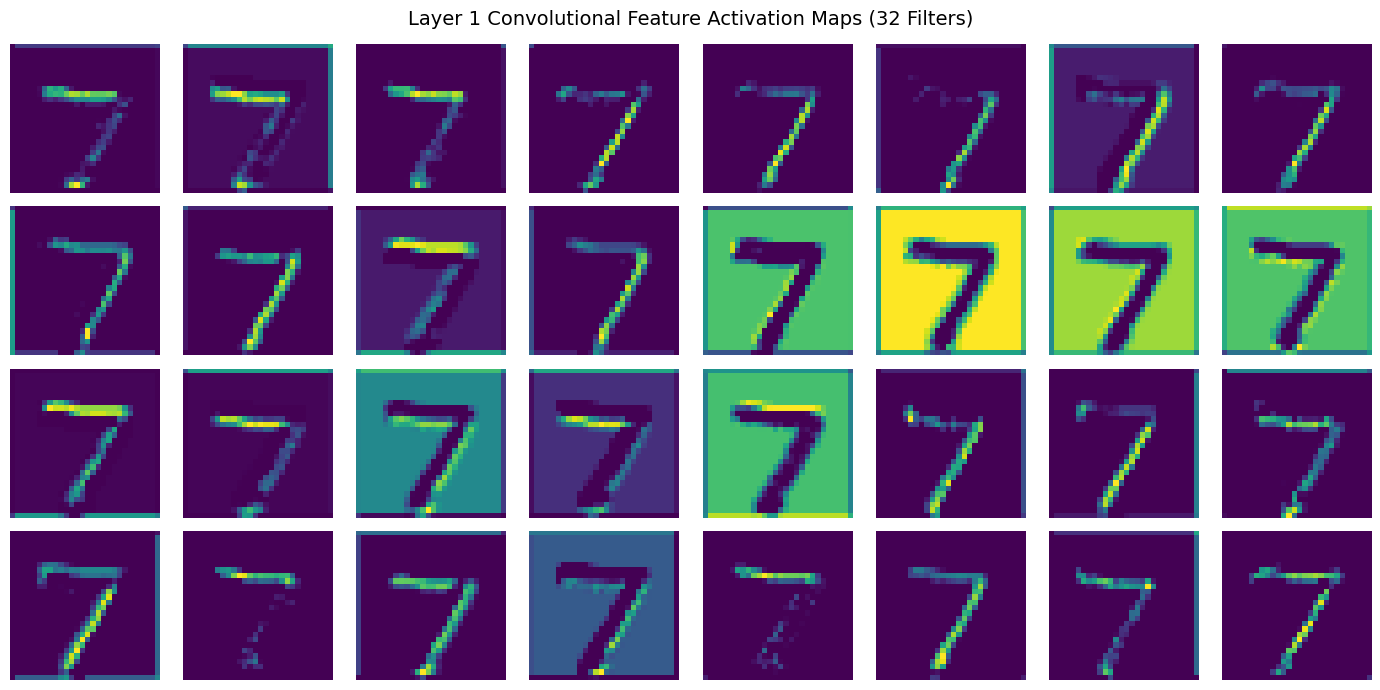

In [14]:
# Feature Activation Map Visualizations for Conv1 Layer
# Extracts and visualizes intermediate activations generated by the first convolutional layer.

import matplotlib.pyplot as plt

model.eval()
# Index test_dataset[0] to extract the first (image, label) tuple
sample_image, _ = test_dataset[0]
img_input = sample_image.unsqueeze(0).to(device)

with torch.no_grad():
    conv1_activation = torch.relu(model.conv1(img_input))

# Plot 32 feature maps from Conv1
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
fig.suptitle("Layer 1 Convolutional Feature Activation Maps (32 Filters)", fontsize=14)

for i, ax in enumerate(axes.flat):
    if i < conv1_activation.shape[1]:
        ax.imshow(conv1_activation[0, i].cpu().numpy(), cmap='viridis')
    ax.axis('off')

plt.tight_layout()
plt.show()